In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Google Colab
PATH = Path("/content/data")

# Local (comment the line above and uncomment below)
# PATH = Path("diplomacy-deception-detection/data/raw")

for name in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    print(name, ":", (PATH / name).exists())

train.jsonl : True
validation.jsonl : True
test.jsonl : True


In [3]:
def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))
    return records

In [4]:
splits = {}
for split in ["train", "validation", "test"]:
    splits[split] = read_jsonl(PATH / f"{split}.jsonl")
    print(f"{split}: {len(splits[split])} conversations")

train: 189 conversations
validation: 21 conversations
test: 42 conversations


#### message-level label table

For class imbalance analysis, we need only the split, game, sender label, receiver label, and message text. Each row is one message.

In [5]:
rows = []

for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        n = len(record["messages"])
        if len(record["sender_labels"]) != n or len(record["receiver_labels"]) != n:
            raise ValueError(f"Label alignment problem: {split}, conversation {conversation_index}")

        for i in range(n):
            rows.append({
                "split": split,
                "game_id": record["game_id"],
                "conversation_index": conversation_index,
                "message": record["messages"][i],
                "sender_label": record["sender_labels"][i],
                "receiver_label": record["receiver_labels"][i]
            })

df = pd.DataFrame(rows)
df.shape


(17289, 6)

In [6]:
display(df.head())

,split,game_id,conversation_index,message,sender_label,receiver_label
0,train,1,0,Germany!\n\nJust the person I want to speak wi...,True,True
1,train,1,0,"You've whet my appetite, Italy. What's the sug...",True,True
2,train,1,0,👍,True,True
3,train,1,0,It seems like there are a lot of ways that cou...,True,True
4,train,1,0,"Yeah, I can’t say I’ve tried it and it works, ...",True,NOANNOTATION


#### Check available label values

Verify the labels before calculating any ratios. Do not treat NOANNOTATION as a negative class.

In [7]:
# Sender labels
df["sender_label"].value_counts(dropna=False).to_frame("count")

,count
sender_label,
True,16402
False,887


In [8]:
# Receiver labels
df["receiver_label"].value_counts(dropna=False).to_frame("count")

,count
receiver_label,
True,15005
NOANNOTATION,1506
False,778


In [9]:
sender_valid = df["sender_label"].map(lambda x: type(x) is bool)
receiver_valid = df["receiver_label"].map(
    lambda x: type(x) is bool or x == "NOANNOTATION"
)

print("Unexpected sender labels:", (~sender_valid).sum())
print("Unexpected receiver labels:", (~receiver_valid).sum())

Unexpected sender labels: 0
Unexpected receiver labels: 0


#### sender-label distribution

In [10]:
sender_df = df.loc[sender_valid].copy()
sender_df["class"] = sender_df["sender_label"].map({True: "Truthful", False: "Deceptive"})

overall = sender_df["class"].value_counts().reindex(
    ["Truthful", "Deceptive"], fill_value=0
)
overall_table = pd.DataFrame({
    "count": overall,
    "percentage": (overall / overall.sum() * 100).round(2)
})
display(overall_table)

,count,percentage
class,,
Truthful,16402,94.87
Deceptive,887,5.13


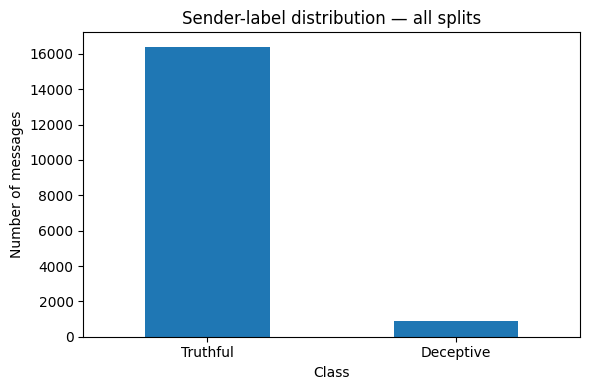

In [11]:
plt.figure(figsize=(6, 4))
overall.plot.bar()
plt.title("Sender-label distribution — all splits")
plt.ylabel("Number of messages")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Compare sender-label distributions across splits

Check whether train, validation, and test have similar class proportions.

In [12]:
split_counts = pd.crosstab(sender_df["split"], sender_df["class"]).reindex(
    index=["train", "validation", "test"],
    columns=["Truthful", "Deceptive"], fill_value=0
)
split_percent = split_counts.div(split_counts.sum(axis=1), axis=0) * 100

print("Message counts:")
display(split_counts)

Message counts:


class,Truthful,Deceptive
split,,
train,12541,591
validation,1360,56
test,2501,240


In [13]:
print("Percentages within each split:")
display(split_percent.round(2))


Percentages within each split:


class,Truthful,Deceptive
split,,
train,95.50,4.50
validation,96.05,3.95
test,91.24,8.76


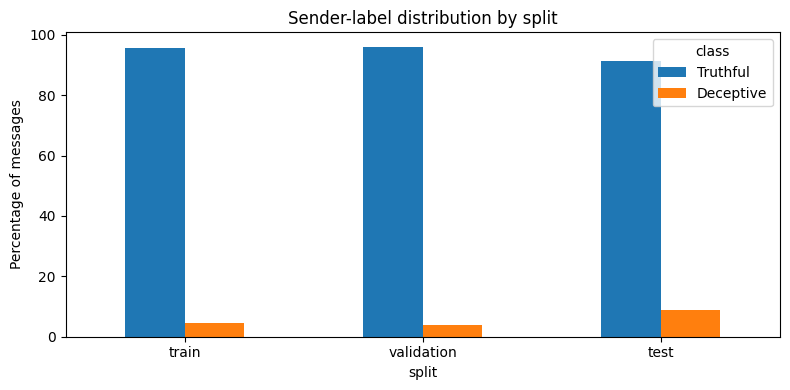

In [14]:
split_percent.plot.bar(figsize=(8, 4))
plt.ylabel("Percentage of messages")
plt.title("Sender-label distribution by split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Calculate imbalance ratio

**Imbalance ratio = truthful messages / deceptive messages.** Larger values mean lies are rarer. Avoid division by zero when a split has no deceptive messages.

In [15]:
imbalance_rows = []

for split, row in split_counts.iterrows():
    truthful = int(row["Truthful"])
    deceptive = int(row["Deceptive"])
    imbalance_rows.append({
        "split": split,
        "truthful": truthful,
        "deceptive": deceptive,
        "deceptive_percent": round(100 * deceptive / (truthful + deceptive), 2)
            if truthful + deceptive else None,
        "truthful_to_deceptive_ratio": round(truthful / deceptive, 2)
            if deceptive else None
    })

imbalance_df = pd.DataFrame(imbalance_rows)
display(imbalance_df)

,split,truthful,deceptive,deceptive_percent,truthful_to_deceptive_ratio
0,train,12541,591,4.50,21.22
1,validation,1360,56,3.95,24.29
2,test,2501,240,8.76,10.42


#### class distribution by game

A small number of games may have a different deception rate from the overall average.

In [16]:
game_counts = pd.crosstab(
    [sender_df["split"], sender_df["game_id"]], sender_df["class"]
).reindex(columns=["Truthful", "Deceptive"], fill_value=0)

game_counts["total"] = game_counts["Truthful"] + game_counts["Deceptive"]
game_counts["deceptive_percent"] = (
    100 * game_counts["Deceptive"] / game_counts["total"]
).round(2)

display(game_counts.sort_values("deceptive_percent", ascending=False))


class               Truthful  Deceptive  total  deceptive_percent
split      game_id                                               
test       4            1353        193   1546              12.48
train      5             386         41    427               9.60
           6             471         50    521               9.60
           1            2399        219   2618               8.37
           7             958         45   1003               4.49
validation 11           1360         56   1416               3.95
test       12           1148         47   1195               3.93
train      10            801         30    831               3.61
           9            1555         56   1611               3.48
           8             878         27    905               2.98
           2            3224         78   3302               2.36
           3            1869         45   1914               2.35

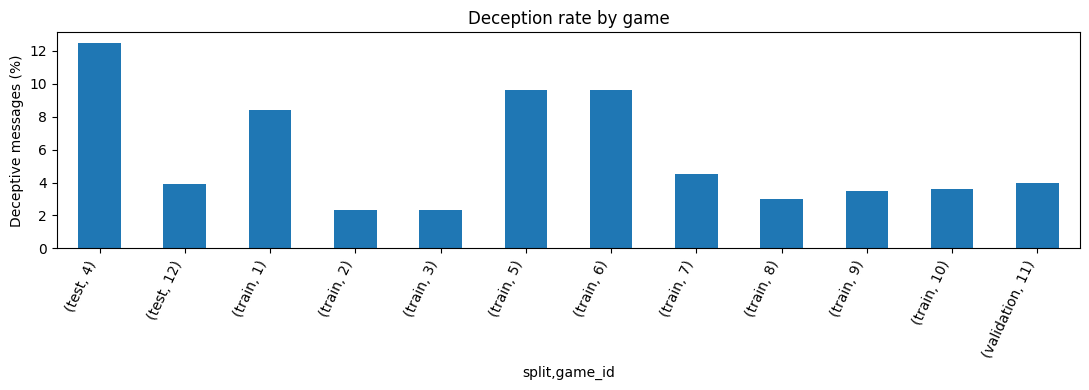

In [17]:
game_counts["deceptive_percent"].plot.bar(figsize=(11, 4))
plt.ylabel("Deceptive messages (%)")
plt.title("Deception rate by game")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

#### Compare receiver annotations separately

Receiver labels reflect perceived truthfulness, not ground-truth deception. We exclude NOANNOTATION when calculating receiver-judgment percentages, but report how much is missing.

In [18]:
receiver_counts = pd.crosstab(
    df["split"], df["receiver_label"].astype(str)
).reindex(index=["train", "validation", "test"], fill_value=0)

display(receiver_counts)



receiver_label,False,NOANNOTATION,True
split,,,
train,566,1107,11459
validation,47,133,1236
test,165,266,2310


In [19]:
annotated = df[df["receiver_label"].map(lambda x: type(x) is bool)].copy()
annotated["receiver_class"] = annotated["receiver_label"].map({
    True: "Believed truthful",
    False: "Suspected deceptive"
})

receiver_percent = pd.crosstab(
    annotated["split"], annotated["receiver_class"], normalize="index"
) * 100
display(receiver_percent.round(2))


receiver_class,Believed truthful,Suspected deceptive
split,,
test,93.33,6.67
train,95.29,4.71
validation,96.34,3.66


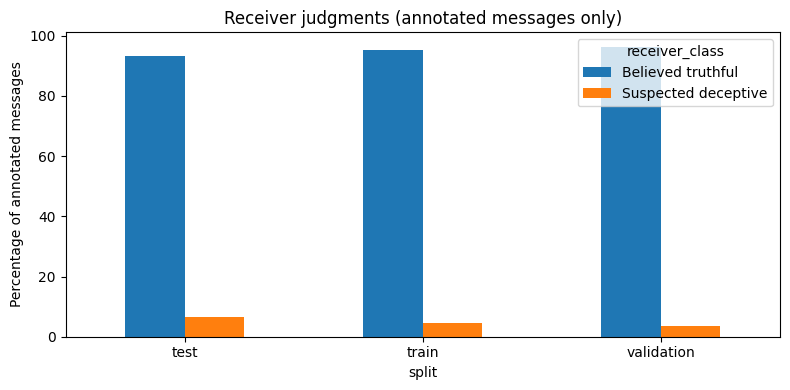

In [20]:

if not receiver_percent.empty:
    receiver_percent.plot.bar(figsize=(8, 4))
    plt.title("Receiver judgments (annotated messages only)")
    plt.ylabel("Percentage of annotated messages")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

#### Compare sender truthfulness and receiver judgment

This cross-tab explores agreement between the sender's actual label and the receiver's judgment. **Only receiver-annotated messages** are included.

In [21]:
comparison = df[
    df["sender_label"].map(lambda x: type(x) is bool)
    & df["receiver_label"].map(lambda x: type(x) is bool)
].copy()

comparison["actual"] = comparison["sender_label"].map({
    True: "Truthful", False: "Deceptive"
})
comparison["perceived"] = comparison["receiver_label"].map({
    True: "Believed truthful", False: "Suspected deceptive"
})

agreement_table = pd.crosstab(comparison["actual"], comparison["perceived"])
display(agreement_table)

perceived,Believed truthful,Suspected deceptive
actual,,
Deceptive,691,111
Truthful,14314,667


In [22]:
if len(comparison):
    agreement = (comparison["sender_label"] == comparison["receiver_label"]).mean() * 100
    print(f"Sender/receiver label agreement (annotated only): {agreement:.2f}%")

Sender/receiver label agreement (annotated only): 91.40%


#### Calculate a simple majority-class baseline

A model that predicts truthful for every message can achieve high accuracy when deception is rare. This is why accuracy alone can be misleading.

In [23]:
baseline_rows = []

for split, row in split_counts.iterrows():
    total = int(row.sum())
    majority = int(row.max())
    baseline_rows.append({
        "split": split,
        "total_messages": total,
        "majority_class": row.idxmax(),
        "majority_baseline_accuracy_percent": round(100 * majority / total, 2)
            if total else None
    })

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)

,split,total_messages,majority_class,majority_baseline_accuracy_percent
0,train,13132,Truthful,95.50
1,validation,1416,Truthful,96.05
2,test,2741,Truthful,91.24
